
# Oil and Gas Production Analysis – Data Visualization

## 1. Project Introduction

This notebook focuses on the visual presentation of findings from the 2024 Oil and Gas Production Analysis project.

Using Python and Matplotlib, the analysis presents production trends, compares well and operator performance, and examines relationships between oil, gas, and water production.

The visualizations are designed to communicate important patterns and findings from the dataset in a clear and meaningful way.

## 2. Objectives

The objectives of this notebook are to:

1. Visualize monthly oil, gas, water, and injection production trends.
2. Compare production performance across wells.
3. Compare production contributions across operators.
4. Visualize relationships between oil, gas, and water production.
5. Present Water-Oil Ratio (WOR) patterns across wells.
6. Communicate key production insights through appropriate charts.

## 3. Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook


## 2. Data Loading and Preparation

This section covers the libraries required for the visualization process and the loading and preparation of the 2024 OGOR-A dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
columns = [
    "lease_number",
    "completion_name",
    "production_date",
    "days_on_prod",
    "product_code",
    "monthly_oil_volume",
    "monthly_gas_volume",
    "monthly_water_volume",
    "api_well_number",
    "well_status_code",
    "area_block",
    "operator_number",
    "operator_name",
    "field_name_code",
    "injection_volume",
    "production_interval_code",
    "first_production_date",
    "unit_agreement_number",
    "unit_allocation_suffix"
]

# Locate the dataset
possible_paths = [
    Path("data") / "ogora2024delimit.txt",
    Path("..") / "data" / "ogora2024delimit.txt"
]

data_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError("Dataset not found. Check your data folder.")

# Load the dataset
df = pd.read_csv(
    data_path,
    sep=",",
    header=None,
    names=columns,
    dtype=str
)

# Convert numerical columns
numeric_columns = [
    "days_on_prod",
    "monthly_oil_volume",
    "monthly_gas_volume",
    "monthly_water_volume",
    "injection_volume"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Dataset loaded and prepared successfully!")
print("Dataset shape:", df.shape)

Dataset loaded and prepared successfully!
Dataset shape: (62836, 19)


In [3]:
df.head()

,lease_number,completion_name,production_date,days_on_prod,product_code,monthly_oil_volume,monthly_gas_volume,monthly_water_volume,api_well_number,well_status_code,area_block,operator_number,operator_name,field_name_code,injection_volume,production_interval_code,first_production_date,unit_agreement_number,unit_allocation_suffix
0,00016,E002,202401,0,O,0,0,0,177190022500,12,WD 31,03151,COX OPERATING LLC,WD030,0,Q04,19720331,NaN,NaN
1,00016,E002D,202401,0,O,0,0,0,177190022500,12,WD 31,03151,COX OPERATING LLC,WD030,0,Q01,19610228,NaN,NaN
2,00016,E002Q,202401,0,O,0,0,0,177190022500,12,WD 31,03151,COX OPERATING LLC,WD030,0,Q64,NaN,NaN,NaN
3,00016,E002T,202401,0,O,0,0,0,177190022500,12,WD 31,03151,COX OPERATING LLC,WD030,0,Q65,NaN,NaN,NaN
4,00016,E016,202401,0,G,0,0,0,177194064700,13,WD 31,03151,COX OPERATING LLC,WD030,0,S03,20000605,NaN,NaN


In [4]:
df.dtypes

lease_number                object
completion_name             object
production_date             object
days_on_prod                 int64
product_code                object
monthly_oil_volume           int64
monthly_gas_volume           int64
monthly_water_volume         int64
api_well_number             object
well_status_code            object
area_block                  object
operator_number             object
operator_name               object
field_name_code             object
injection_volume             int64
production_interval_code    object
first_production_date       object
unit_agreement_number       object
unit_allocation_suffix      object
dtype: object

## 3. Monthly Production Trends

This section examines how oil, gas, water, and injection volumes changed throughout 2024.

Monthly production trends help identify periods of increased or decreased production and provide an overview of production performance over time.

In [5]:
monthly_production = df.groupby("production_date").agg(
    total_oil=("monthly_oil_volume", "sum"),
    total_gas=("monthly_gas_volume", "sum"),
    total_water=("monthly_water_volume", "sum"),
    total_injection=("injection_volume", "sum")
).reset_index()

monthly_production

,production_date,total_oil,total_gas,total_water,total_injection
0,202401,54389450,61175454,33721753,16478830
1,202402,52667184,56305118,30187516,15662977
2,202403,55955176,55946856,33308166,16299667
3,202404,55791282,58296677,32241622,15910242
4,202405,55902618,55369683,34140565,18043860
5,202406,54632345,56775058,32846127,16327191
6,202407,56845228,60181436,34309947,19445160
7,202408,57156809,60724077,35490860,20075642
8,202409,48320873,49616309,28129357,15014683
9,202410,56265376,59935795,34189776,20034142


### 3.1 Monthly Oil Production Trend

This chart illustrates the variation in total oil production across the twelve months of 2024. It helps identify production peaks, declines, and general trends throughout the year.

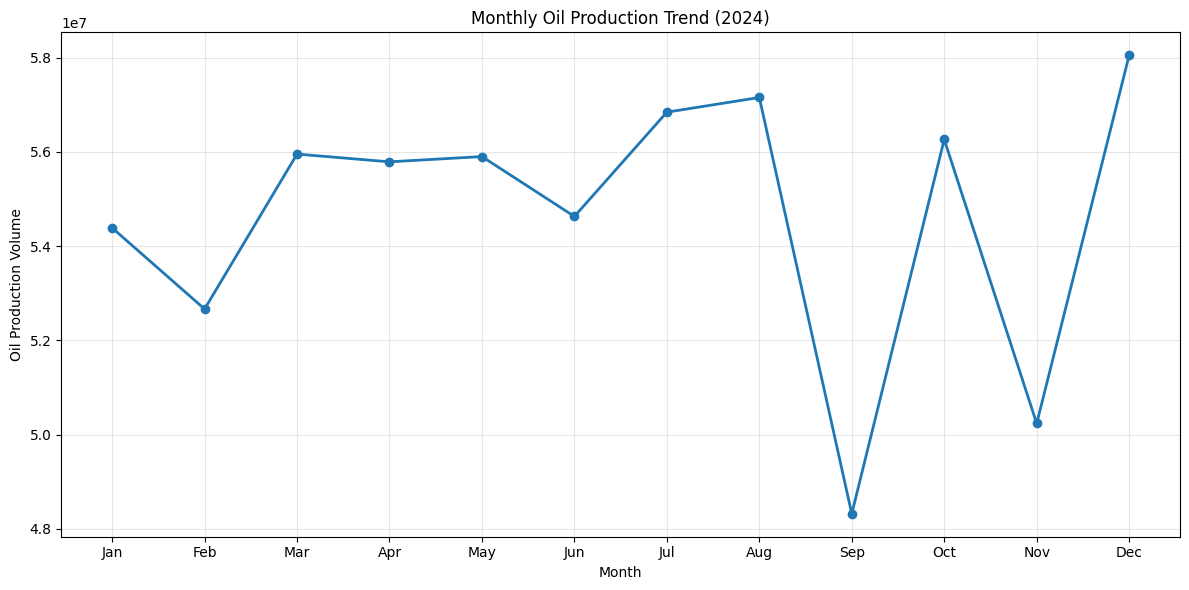

In [6]:
months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 6))

plt.plot(
    months,
    monthly_production["total_oil"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Oil Production Trend (2024)")
plt.xlabel("Month")
plt.ylabel("Oil Production Volume")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 3.2 Monthly Gas Production Trend

This chart shows the variation in total gas production across the twelve months of 2024. It helps identify periods of high and low gas production and compare production performance throughout the year.

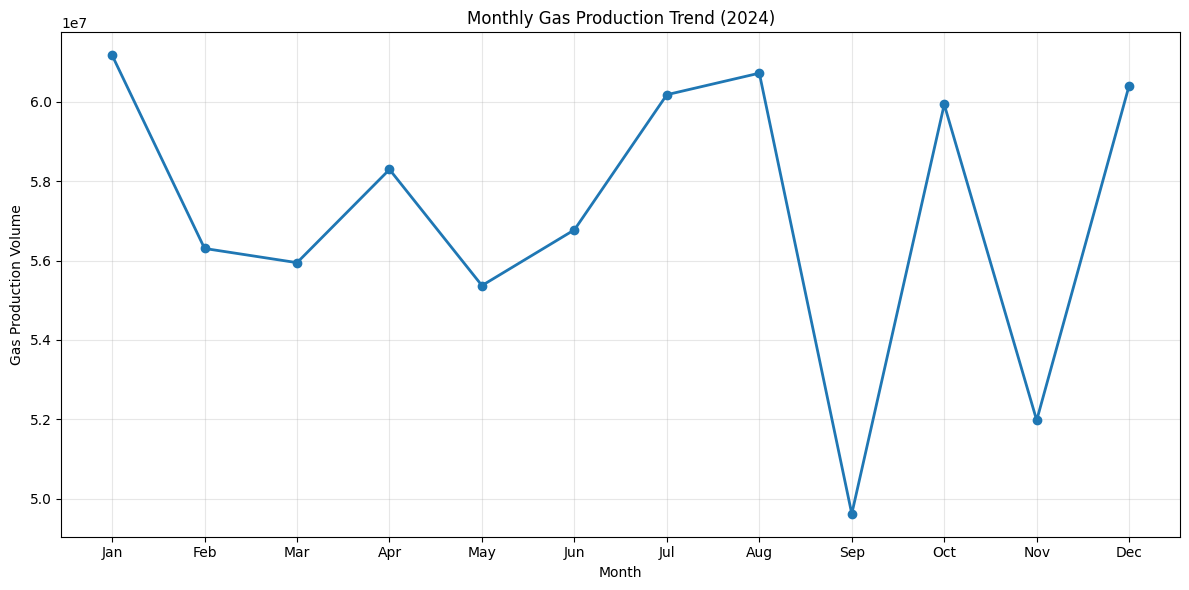

In [7]:
plt.figure(figsize=(12, 6))

plt.plot(
    months,
    monthly_production["total_gas"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Gas Production Trend (2024)")
plt.xlabel("Month")
plt.ylabel("Gas Production Volume")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 3.3 Monthly Water Production Trend

This chart illustrates the variation in total water production across the twelve months of 2024. It helps identify changes in water production and periods of increased or decreased water output.

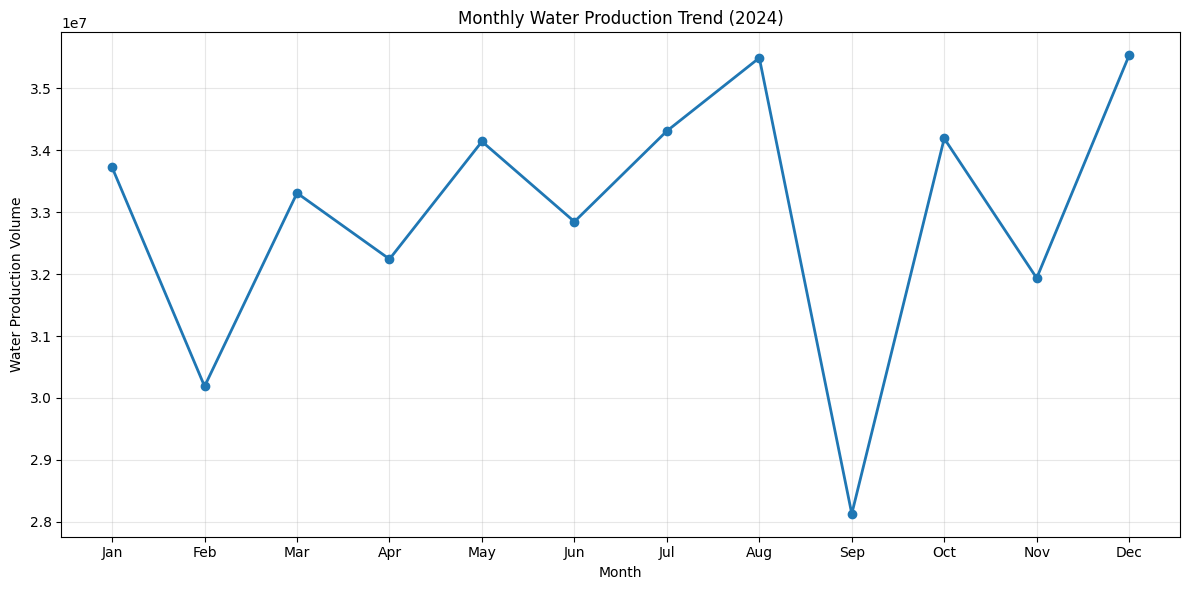

In [8]:
plt.figure(figsize=(12, 6))

plt.plot(
    months,
    monthly_production["total_water"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Water Production Trend (2024)")
plt.xlabel("Month")
plt.ylabel("Water Production Volume")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 3.4 Monthly Injection Production Trend

This chart shows the variation in total injection volume across the twelve months of 2024. It helps identify changes in injection activity and periods of increased or reduced injection volume.

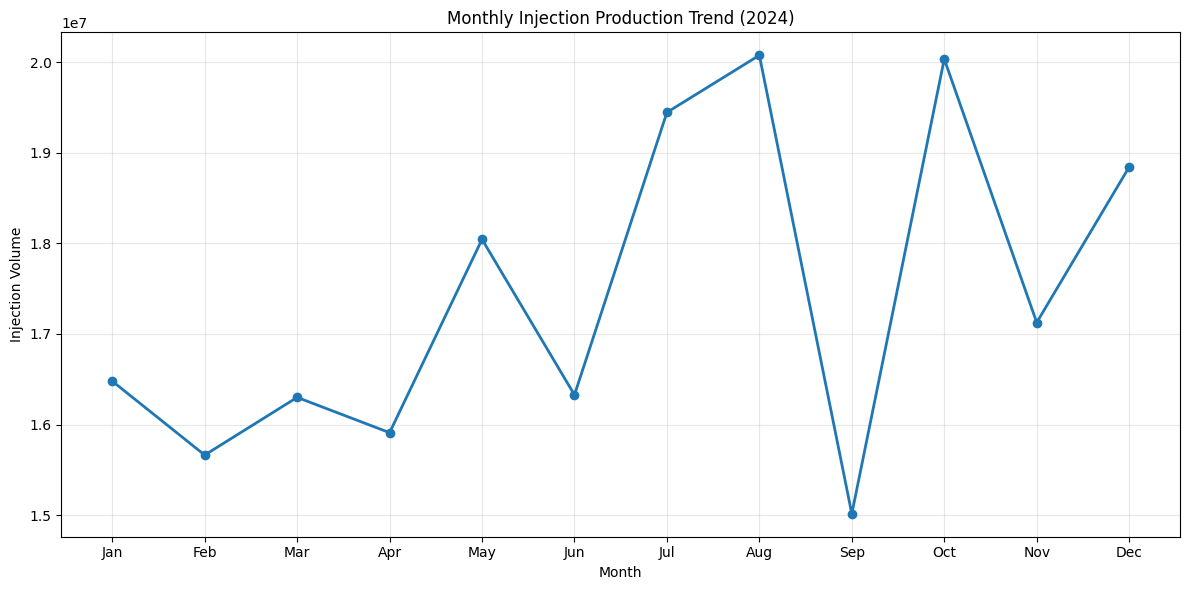

In [9]:
plt.figure(figsize=(12, 6))

plt.plot(
    months,
    monthly_production["total_injection"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Injection Production Trend (2024)")
plt.xlabel("Month")
plt.ylabel("Injection Volume")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 3.5 Comparison of Monthly Production Trends

This visualization compares the relative monthly changes in oil, gas, water, and injection volumes throughout 2024.

Each production variable is indexed to January (100), allowing their relative trends to be compared without directly comparing their absolute production volumes.

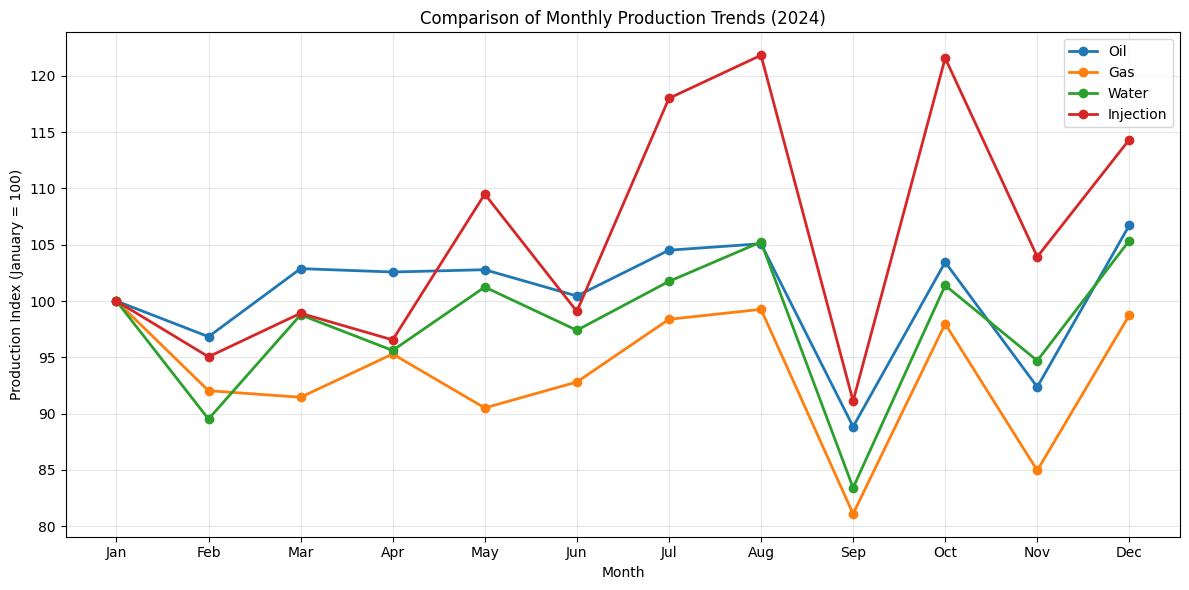

In [10]:
production_index = monthly_production[
    ["total_oil", "total_gas", "total_water", "total_injection"]
].div(
    monthly_production[
        ["total_oil", "total_gas", "total_water", "total_injection"]
    ].iloc[0]
).mul(100)

production_index.index = months

plt.figure(figsize=(12, 6))

for column in production_index.columns:
    plt.plot(
        months,
        production_index[column],
        marker="o",
        linewidth=2,
        label=column.replace("total_", "").title()
    )

plt.title("Comparison of Monthly Production Trends (2024)")
plt.xlabel("Month")
plt.ylabel("Production Index (January = 100)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Well Production Analysis

This section evaluates production performance across individual wells. Oil, gas, and water production volumes are aggregated by API well number to identify the highest-producing wells and compare their production characteristics.

In [11]:
well_production = df.groupby("api_well_number").agg(
    total_oil=("monthly_oil_volume", "sum"),
    total_gas=("monthly_gas_volume", "sum"),
    total_water=("monthly_water_volume", "sum")
).reset_index()

well_production.head()

,api_well_number,total_oil,total_gas,total_water
0,012032016500,0,1141,2
1,012032027100,0,0,0
2,012032029300,880,1892672,33725
3,012032030900,0,0,0
4,177000000600,0,81643,1698


### 4.1 Top 10 Oil-Producing Wells

This visualization identifies the ten wells with the highest cumulative oil production in 2024. It provides a comparison of oil production performance across the leading wells.

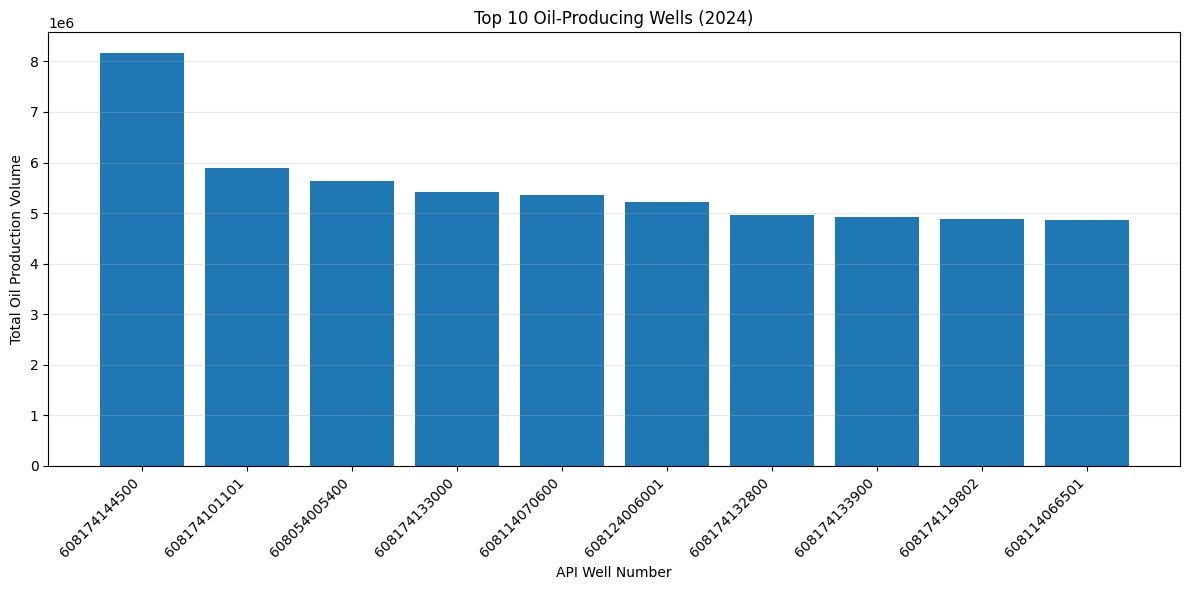

In [12]:
top_10_oil_wells = well_production.sort_values(
    by="total_oil",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_oil_wells["api_well_number"].astype(str),
    top_10_oil_wells["total_oil"]
)

plt.title("Top 10 Oil-Producing Wells (2024)")
plt.xlabel("API Well Number")
plt.ylabel("Total Oil Production Volume")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 4.2 Top 10 Gas-Producing Wells

This visualization identifies the ten wells with the highest cumulative gas production in 2024. It allows us to compare gas production performance across the leading wells.

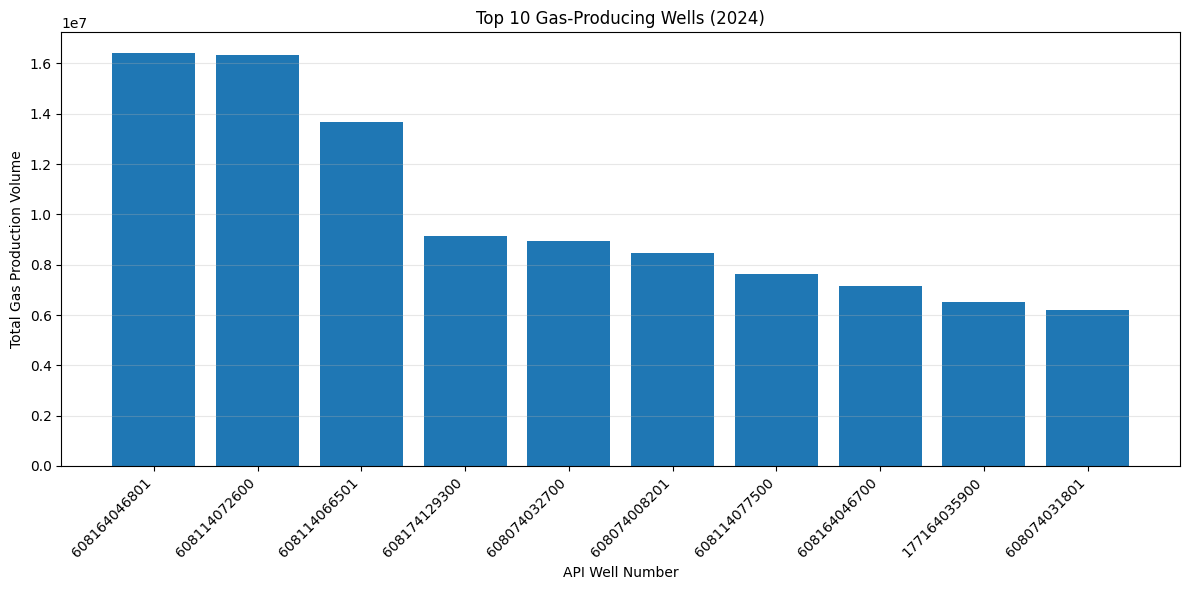

In [13]:
top_10_gas_wells = well_production.sort_values(
    by="total_gas",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_gas_wells["api_well_number"].astype(str),
    top_10_gas_wells["total_gas"]
)

plt.title("Top 10 Gas-Producing Wells (2024)")
plt.xlabel("API Well Number")
plt.ylabel("Total Gas Production Volume")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 4.3 Top 10 Water-Producing Wells

This visualization identifies the ten wells with the highest cumulative water production in 2024. It helps compare water production across wells and identify those contributing the largest water volumes.

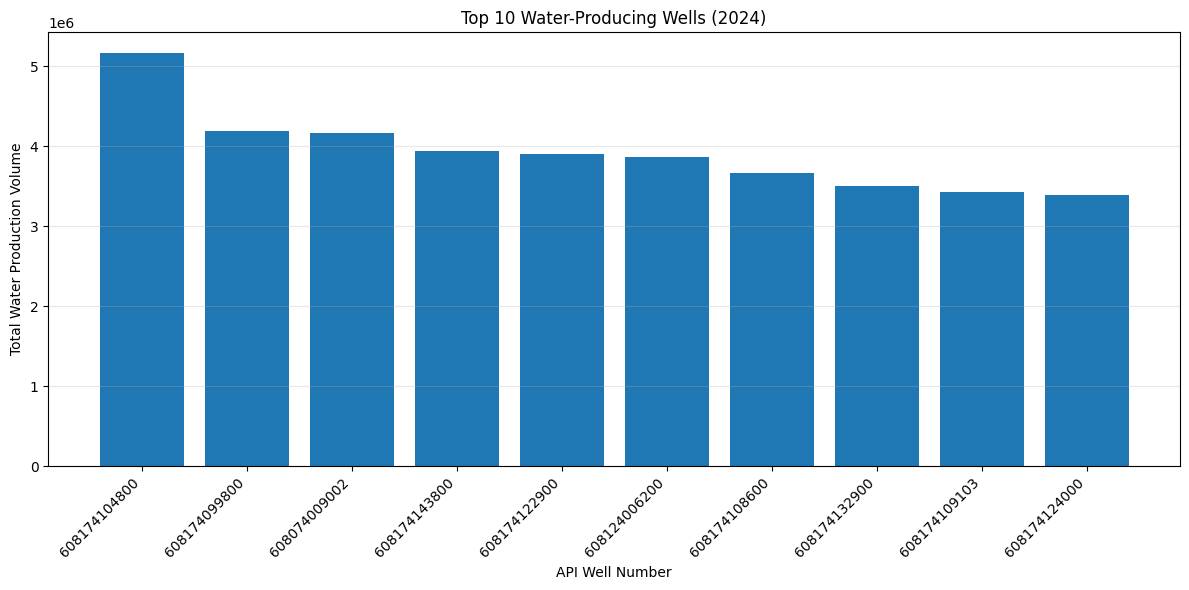

In [14]:
top_10_water_wells = well_production.sort_values(
    by="total_water",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_water_wells["api_well_number"].astype(str),
    top_10_water_wells["total_water"]
)

plt.title("Top 10 Water-Producing Wells (2024)")
plt.xlabel("API Well Number")
plt.ylabel("Total Water Production Volume")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 4.4 Oil-Water Production Relationship

This visualization examines the relationship between oil and water production across individual wells. It helps identify patterns in water production as oil production varies among wells.

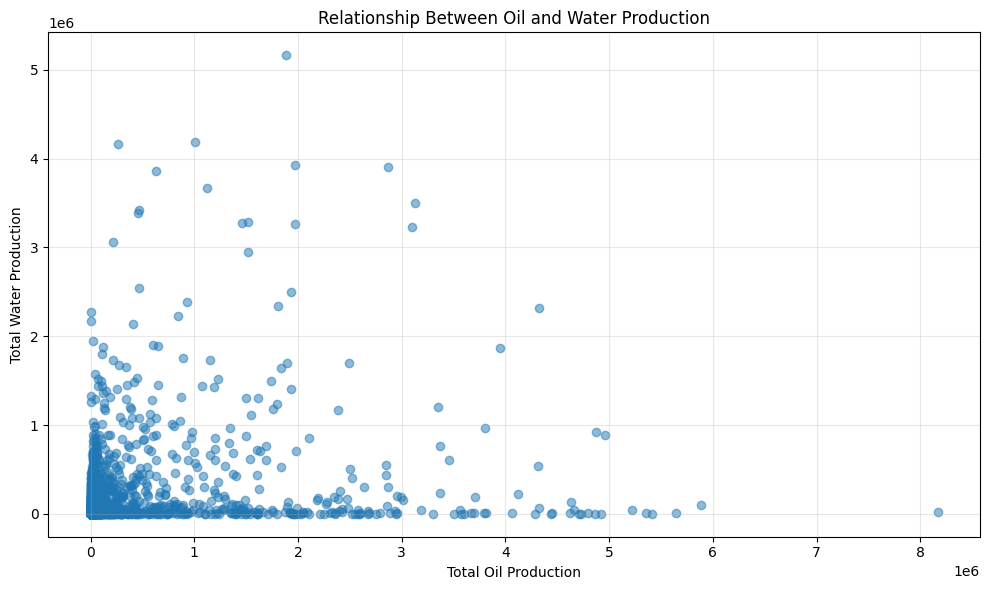

In [15]:
plt.figure(figsize=(10, 6))

plt.scatter(
    well_production["total_oil"],
    well_production["total_water"],
    alpha=0.5
)

plt.title("Relationship Between Oil and Water Production")
plt.xlabel("Total Oil Production")
plt.ylabel("Total Water Production")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 4.5 Oil-Gas Production Relationship

This visualization examines the relationship between oil and gas production across individual wells. It helps identify whether wells with higher oil production also tend to record higher gas production.

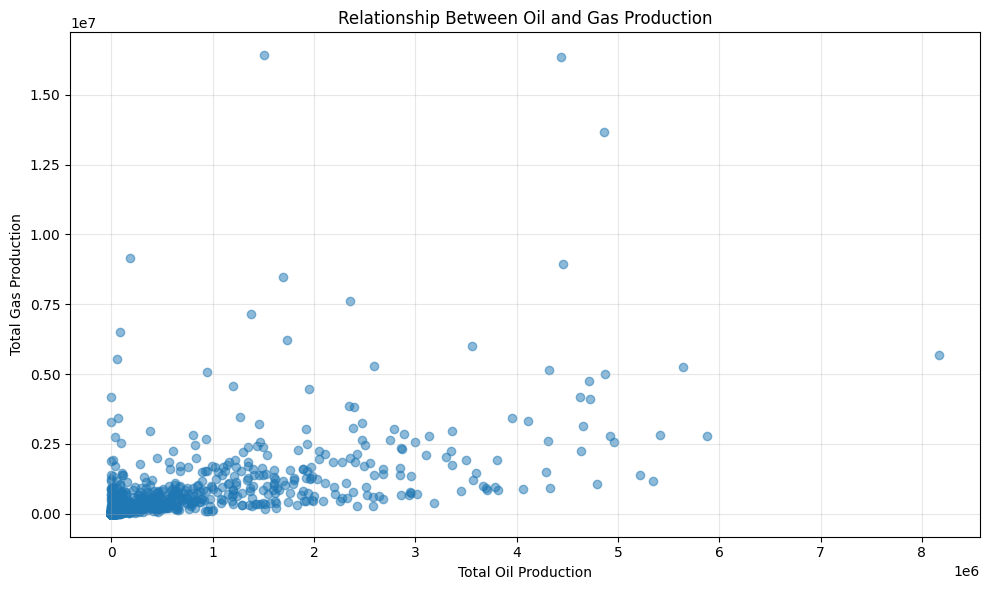

In [16]:
plt.figure(figsize=(10, 6))

plt.scatter(
    well_production["total_oil"],
    well_production["total_gas"],
    alpha=0.5
)

plt.title("Relationship Between Oil and Gas Production")
plt.xlabel("Total Oil Production")
plt.ylabel("Total Gas Production")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 4.6 Comparison of Production Relationships

This section compares the correlation between oil-water production and oil-gas production across individual wells.

Correlation coefficients help measure the strength and direction of the linear relationship between production variables.

In [17]:
oil_water_corr = well_production["total_oil"].corr(
    well_production["total_water"]
)

oil_gas_corr = well_production["total_oil"].corr(
    well_production["total_gas"]
)

print("Oil-Water Correlation:", round(oil_water_corr, 4))
print("Oil-Gas Correlation:", round(oil_gas_corr, 4))

Oil-Water Correlation: 0.283
Oil-Gas Correlation: 0.6469


### 4.7 Visual Comparison of Production Correlations

This chart compares the correlation coefficients of oil-water and oil-gas production relationships. It provides a visual representation of the relative strength of the two linear relationships.

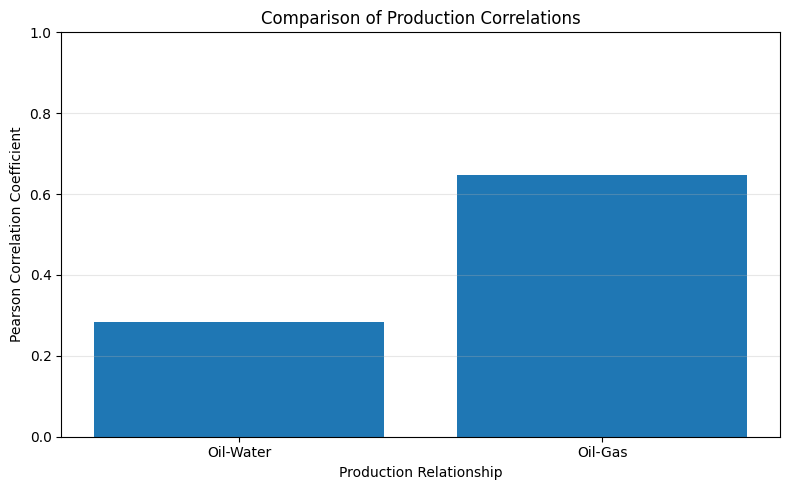

In [18]:
correlation_data = pd.Series({
    "Oil-Water": oil_water_corr,
    "Oil-Gas": oil_gas_corr
})

plt.figure(figsize=(8, 5))

plt.bar(
    correlation_data.index,
    correlation_data.values
)

plt.title("Comparison of Production Correlations")
plt.xlabel("Production Relationship")
plt.ylabel("Pearson Correlation Coefficient")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Water-Oil Ratio (WOR) Analysis

This section examines the Water-Oil Ratio (WOR) across individual wells. WOR measures the volume of water produced relative to the volume of oil produced and helps assess water production behaviour in producing wells.


### 5.1 Water-Oil Ratio Calculation

The Water-Oil Ratio is calculated by dividing total water production by total oil production for each well.

Wells with zero oil production are excluded from the calculation to avoid division by zero.

In [19]:
well_production["WOR"] = np.where(
    well_production["total_oil"] > 0,
    well_production["total_water"] / well_production["total_oil"],
    np.nan
)

well_production[["api_well_number", "total_oil", "total_water", "WOR"]].head(10)

,api_well_number,total_oil,total_water,WOR
0,012032016500,0,2,NaN
1,012032027100,0,0,NaN
2,012032029300,880,33725,38.323864
3,012032030900,0,0,NaN
4,177000000600,0,1698,NaN
5,177000026100,0,0,NaN
6,177000031300,0,0,NaN
7,177002006800,0,0,NaN
8,177002007100,0,0,NaN
9,177004105200,0,0,NaN


### 5.2 Distribution of Water-Oil Ratio Across Wells

This visualization examines the distribution of WOR values across wells with positive oil production. It helps identify the spread of water production relative to oil production and highlights wells with unusually high WOR values.

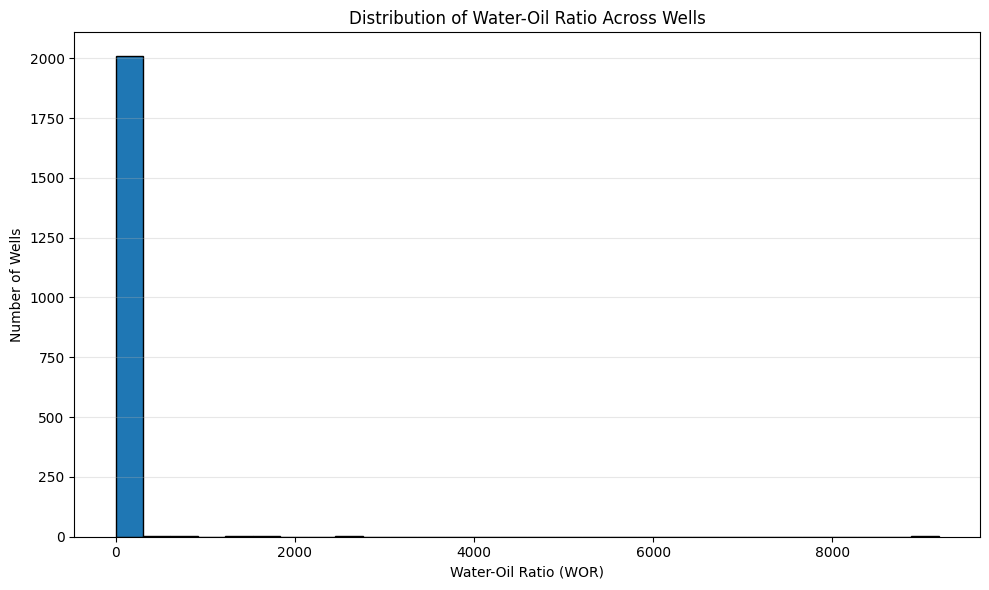

In [20]:
plt.figure(figsize=(10, 6))

plt.hist(
    well_production["WOR"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Water-Oil Ratio Across Wells")
plt.xlabel("Water-Oil Ratio (WOR)")
plt.ylabel("Number of Wells")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 5.3 Top 10 Wells by Water-Oil Ratio

This visualization identifies the ten wells with the highest WOR values among wells with positive oil production. It helps highlight wells with particularly high water production relative to oil production.

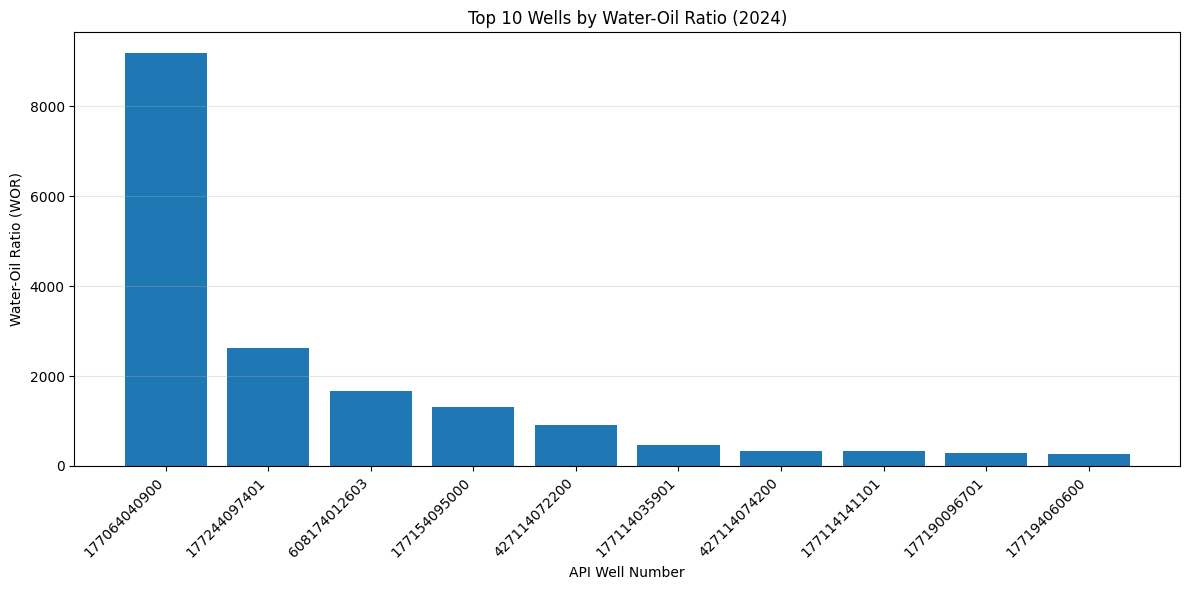

In [21]:
top_10_wor_wells = well_production.dropna(
    subset=["WOR"]
).sort_values(
    by="WOR",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_wor_wells["api_well_number"].astype(str),
    top_10_wor_wells["WOR"]
)

plt.title("Top 10 Wells by Water-Oil Ratio (2024)")
plt.xlabel("API Well Number")
plt.ylabel("Water-Oil Ratio (WOR)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Operator Production Analysis

This section compares oil, gas, and water production across operators. It helps identify the operators contributing the largest production volumes and provides insight into production distribution among operators.

### 6.1 Operator-Level Production Summary

Production volumes are aggregated by operator name to compare their total oil, gas, and water production contributions during 2024.

In [22]:
operator_production = df.groupby("operator_name").agg(
    total_oil=("monthly_oil_volume", "sum"),
    total_gas=("monthly_gas_volume", "sum"),
    total_water=("monthly_water_volume", "sum")
).reset_index()

operator_production.head()

,operator_name,total_oil,total_gas,total_water
0,ANADARKO PETROLEUM CORPORATION,62274557,53813302,21083678
1,ANKOR ENERGY LLC,0,0,0
2,ARENA OFFSHORE LP,8454987,22538514,56596510
3,ARRAY PETROLEUM LLC,991398,3040261,5419676
4,BEACON GROWTHCO OPERATING COMPANY LLC,5590608,7763428,1154202


### 6.2 Top 10 Oil-Producing Operators

This visualization identifies the ten operators with the highest cumulative oil production in 2024. It provides a comparison of oil production contributions across operators.

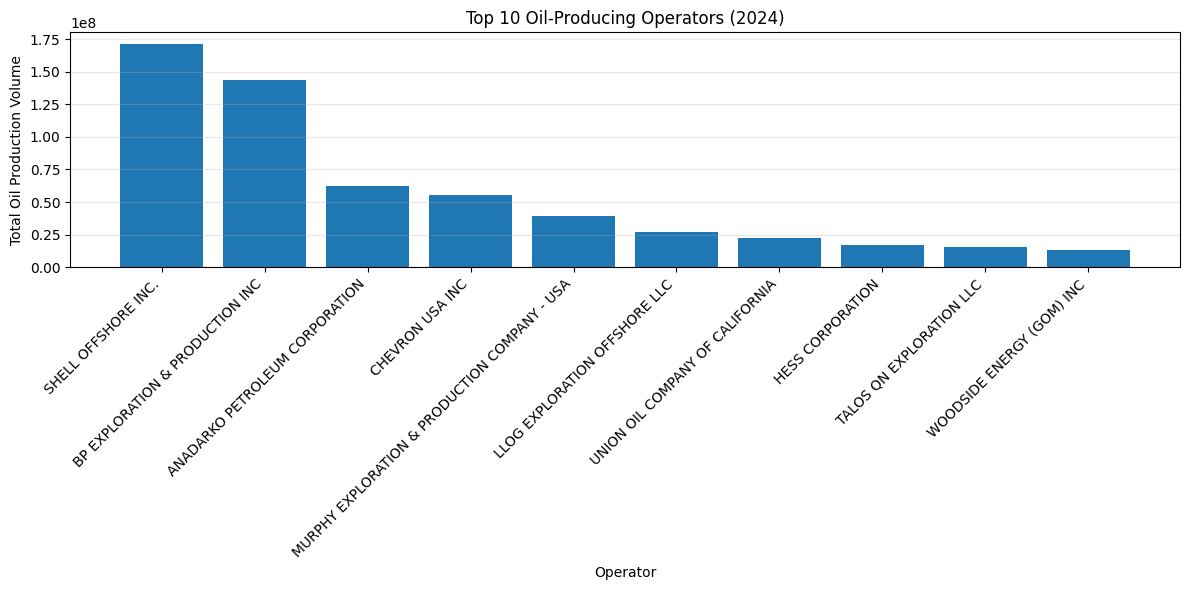

In [23]:
top_10_oil_operators = operator_production.sort_values(
    by="total_oil",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_oil_operators["operator_name"],
    top_10_oil_operators["total_oil"]
)

plt.title("Top 10 Oil-Producing Operators (2024)")
plt.xlabel("Operator")
plt.ylabel("Total Oil Production Volume")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 6.3 Top 10 Gas-Producing Operators

This visualization identifies the ten operators with the highest cumulative gas production in 2024. It allows us to compare gas production contributions across operators.

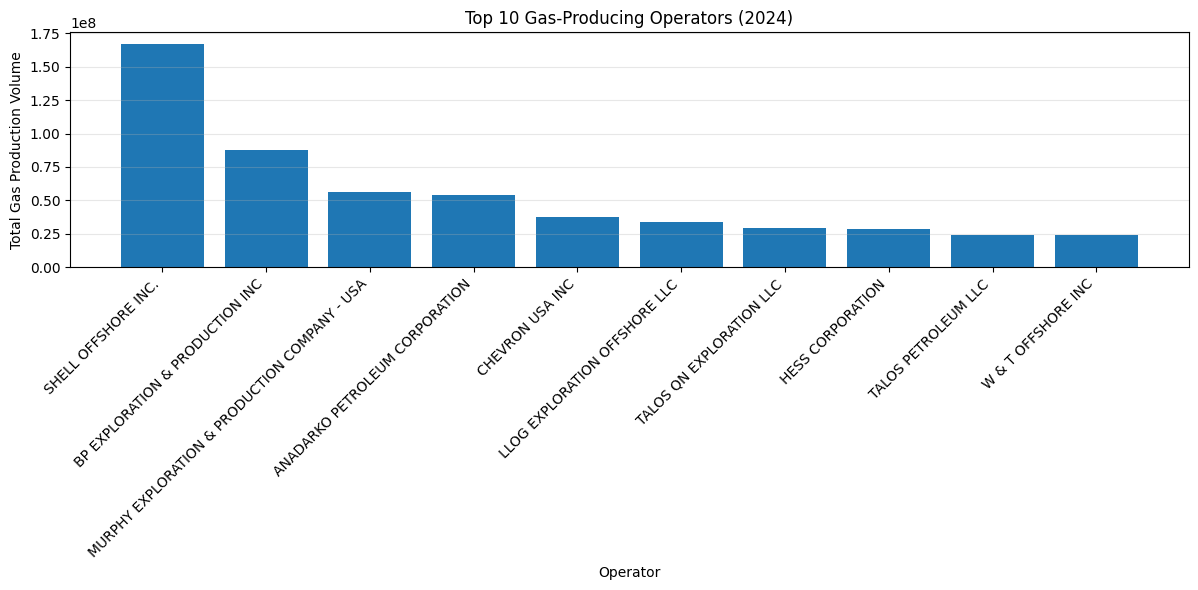

In [24]:
top_10_gas_operators = operator_production.sort_values(
    by="total_gas",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_gas_operators["operator_name"],
    top_10_gas_operators["total_gas"]
)

plt.title("Top 10 Gas-Producing Operators (2024)")
plt.xlabel("Operator")
plt.ylabel("Total Gas Production Volume")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 6.4 Top 10 Water-Producing Operators

This visualization identifies the ten operators with the highest cumulative water production in 2024. It helps compare water production contributions across operators.

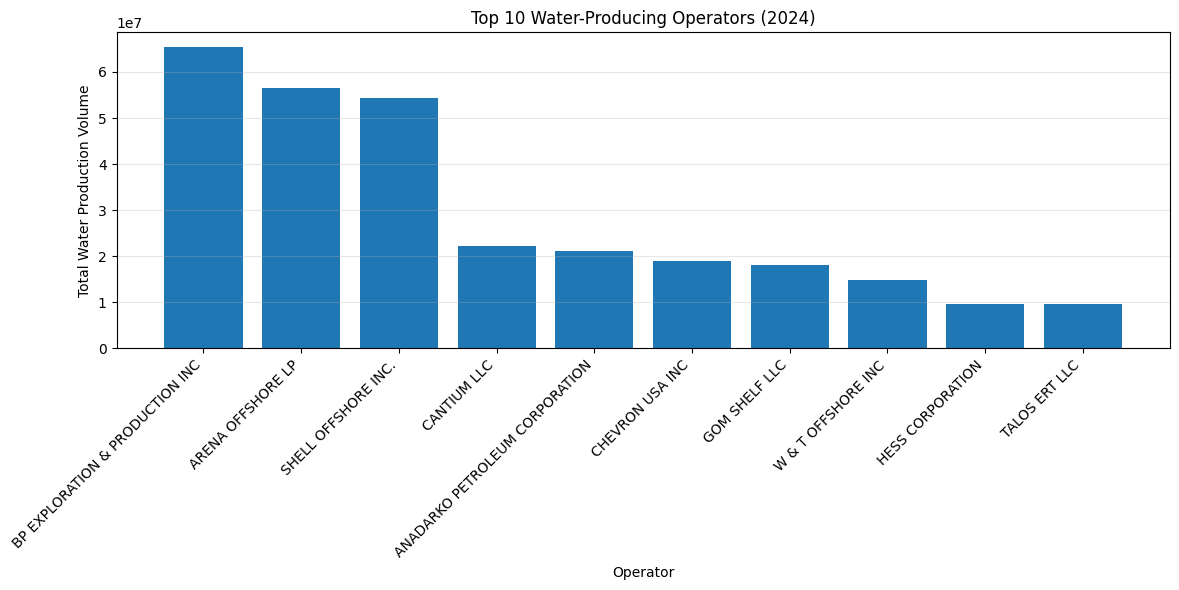

In [25]:
top_10_water_operators = operator_production.sort_values(
    by="total_water",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_water_operators["operator_name"],
    top_10_water_operators["total_water"]
)

plt.title("Top 10 Water-Producing Operators (2024)")
plt.xlabel("Operator")
plt.ylabel("Total Water Production Volume")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 6.5 Comparison of Operator Production Performance

This visualization compares oil, gas, and water production across the ten leading operators. It provides a broader view of how production contributions differ among operators.

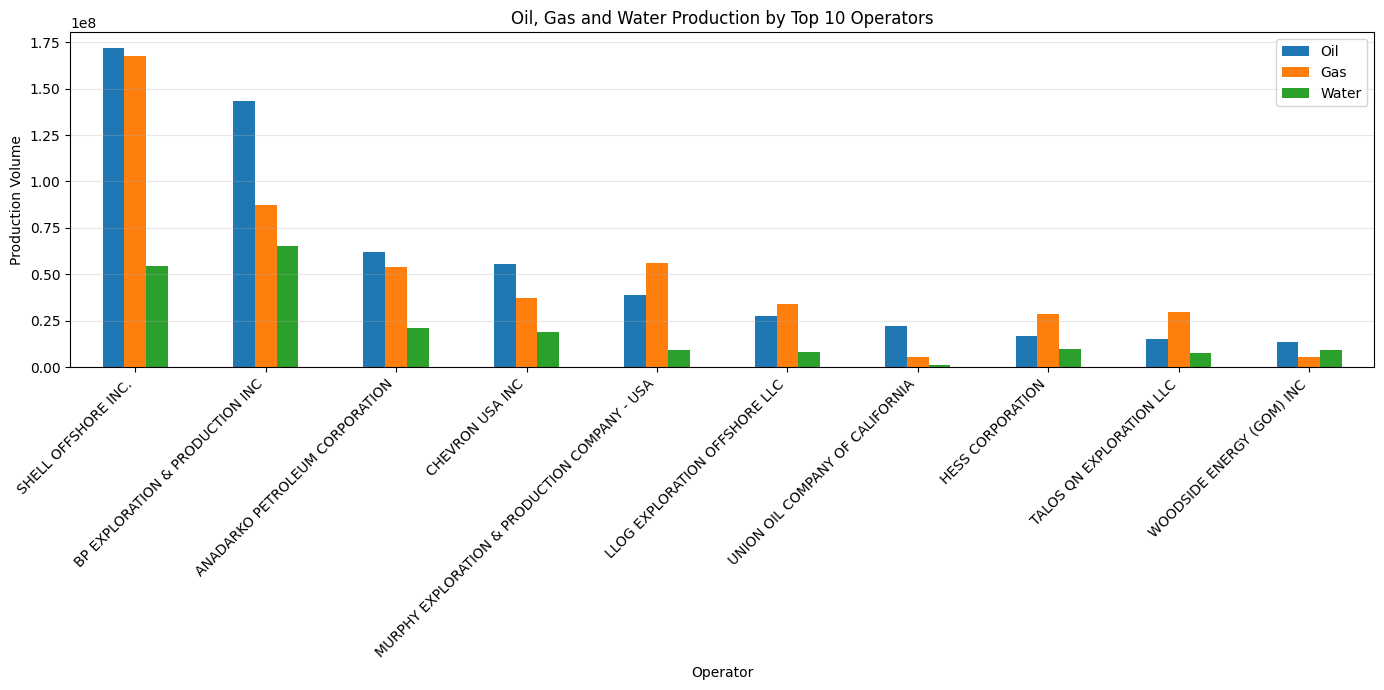

In [26]:
top_10_operators = operator_production.sort_values(
    by="total_oil",
    ascending=False
).head(10)

operator_index = top_10_operators.set_index("operator_name")

operator_index[["total_oil", "total_gas", "total_water"]].plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Oil, Gas and Water Production by Top 10 Operators")
plt.xlabel("Operator")
plt.ylabel("Production Volume")
plt.xticks(rotation=45, ha="right")
plt.legend(["Oil", "Gas", "Water"])
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Key Production Insights

This section summarizes important findings from the visual analysis of the 2024 oil and gas production data. It highlights notable production trends, well performance, operator contributions, and relationships between production variables.

In [27]:
print("KEY PRODUCTION INSIGHTS")

print("\nMonthly Production:")
print("Highest Oil Production:", monthly_production.loc[monthly_production["total_oil"].idxmax(), "production_date"])
print("Lowest Oil Production:", monthly_production.loc[monthly_production["total_oil"].idxmin(), "production_date"])

print("\nTop Producing Wells:")
print("Top Oil Well:", top_10_oil_wells.iloc[0]["api_well_number"])
print("Top Gas Well:", top_10_gas_wells.iloc[0]["api_well_number"])
print("Top Water Well:", top_10_water_wells.iloc[0]["api_well_number"])

print("\nTop Producing Operators:")
print("Top Oil Operator:", top_10_oil_operators.iloc[0]["operator_name"])
print("Top Gas Operator:", top_10_gas_operators.iloc[0]["operator_name"])
print("Top Water Operator:", top_10_water_operators.iloc[0]["operator_name"])

print("\nProduction Relationships:")
print("Oil-Water Correlation:", round(oil_water_corr, 4))
print("Oil-Gas Correlation:", round(oil_gas_corr, 4))

KEY PRODUCTION INSIGHTS

Monthly Production:
Highest Oil Production: 202412
Lowest Oil Production: 202409

Top Producing Wells:
Top Oil Well: 608174144500
Top Gas Well: 608164046801
Top Water Well: 608174104800

Top Producing Operators:
Top Oil Operator: SHELL OFFSHORE INC.
Top Gas Operator: SHELL OFFSHORE INC.
Top Water Operator: BP EXPLORATION & PRODUCTION INC

Production Relationships:
Oil-Water Correlation: 0.283
Oil-Gas Correlation: 0.6469


### 7.1 Interpretation of Key Production Insights

The visual analysis of the 2024 production data revealed the following findings:

1. **Monthly Oil Production:** December recorded the highest oil production, while September recorded the lowest. This indicates a notable decline in production during September.

2. **Well Performance:** Well 608174144500 recorded the highest cumulative oil production, while wells 608164046801 and 608174104800 recorded the highest gas and water production, respectively.

3. **Operator Performance:** SHELL OFFSHORE INC. recorded the highest oil and gas production contributions, while BP EXPLORATION & PRODUCTION INC. recorded the highest water production.

4. **Production Relationships:** Oil and gas production showed a moderate positive correlation of 0.6469, while oil and water production showed a weaker positive correlation of 0.2830.

Overall, the analysis highlights variations in monthly production, differences in well and operator performance, and relationships between the major production variables.

## 8. Conclusion

This project used Python, Pandas, NumPy, and Matplotlib to visualize and examine the 2024 Oil and Gas Production dataset.

The analysis presented monthly production trends, compared well and operator performance, examined relationships between oil, gas, and water production, and investigated Water-Oil Ratio across individual wells.

The visualizations provided a clearer understanding of production patterns and helped identify significant production contributions and variations throughout the year.

This project demonstrates how data visualization can support the interpretation of petroleum production data and communicate useful insights for production analysis and decision-making.